In [34]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import os
os.makedirs('figures', exist_ok=True)
sns.set_theme(style='whitegrid')
pd.set_option('display.width', 200); pd.set_option('display.max_columns', 30)

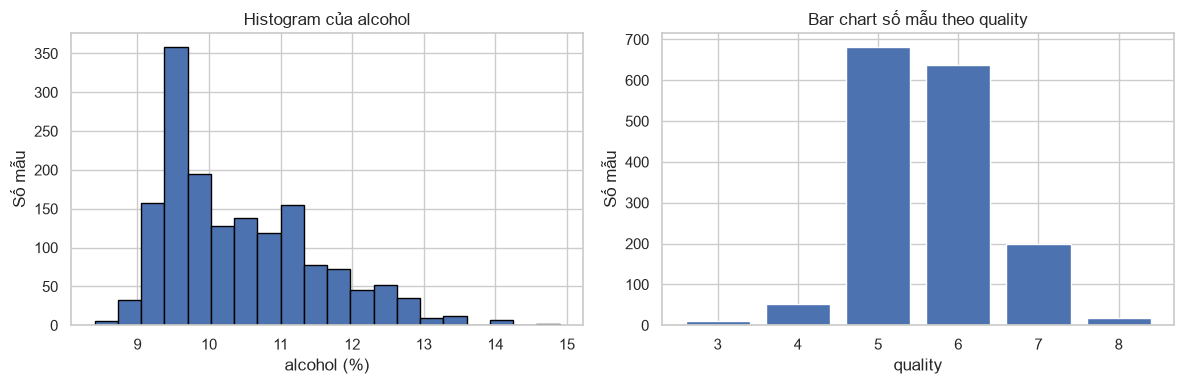

In [35]:
wine = pd.read_csv("data/winequality-red.csv")
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
# Histogram: phân bố nồng độ cồn
ax[0].hist(wine['alcohol'], bins=20, edgecolor='black')
ax[0].set_title('Histogram của alcohol'); ax[0].set_xlabel('alcohol (%)'); ax[0].set_ylabel('Số mẫu')
# Bar chart: số mẫu theo chất lượng
counts = wine['quality'].value_counts().sort_index()
ax[1].bar(counts.index.astype(str), counts.values)
ax[1].set_title('Bar chart số mẫu theo quality'); ax[1].set_xlabel('quality'); ax[1].set_ylabel('Số mẫu')
plt.tight_layout(); plt.show()

In [36]:
fig, ax = plt.subplots(figsize=(6, 4))
ax.hist(wine['alcohol'], bins=20, edgecolor='black'); ax.set_title('Histogram của alcohol')
fig.savefig('figures/vi_du_alcohol.png', dpi=300, bbox_inches='tight')   # ảnh PNG cho báo cáo
fig.savefig('figures/vi_du_alcohol.pdf', bbox_inches='tight')            # PDF vector
# Plotly: fig_plotly.write_html('figures/vi_du.html')
plt.close(fig)
print(sorted(f for f in os.listdir('figures') if f.startswith('vi_du')))

['vi_du_alcohol.pdf', 'vi_du_alcohol.png']


## Bài toán 1 – Nhiệm vụ 1: Trực quan hóa giá nhà Amsterdam

In [37]:
houseprices_data = pd.read_csv("data/HousingPrices-Amsterdam-August-2021.csv")
houseprices_data = houseprices_data[['Zip', 'Price', 'Area', 'Room']]
# Tạo biến PriceperSqm từ Price và Area
houseprices_data['PriceperSqm'] = houseprices_data['Price'] / houseprices_data['Area']
print(houseprices_data.shape, "| giá trị thiếu:", houseprices_data.isna().sum().to_dict())
houseprices_data.head()

(924, 5) | giá trị thiếu: {'Zip': 0, 'Price': 4, 'Area': 0, 'Room': 0, 'PriceperSqm': 4}


,Zip,Price,Area,Room,PriceperSqm
0,1091 CR,685000.0,64,3,10703.125000
1,1059 EL,475000.0,60,3,7916.666667
2,1097 SM,850000.0,109,4,7798.165138
3,1060 TH,580000.0,128,6,4531.250000
4,1036 KN,720000.0,138,5,5217.391304


In [38]:
houseprices_sorted = houseprices_data.sort_values('Price', ascending=False)
houseprices_sorted.head()

,Zip,Price,Area,Room,PriceperSqm
195,1017 EL,5950000.0,394,10,15101.522843
837,1075 AH,5850000.0,480,14,12187.500000
305,1016 AE,4900000.0,623,13,7865.168539
103,1017 ZP,4550000.0,497,13,9154.929577
179,1012 JS,4495000.0,178,5,25252.808989


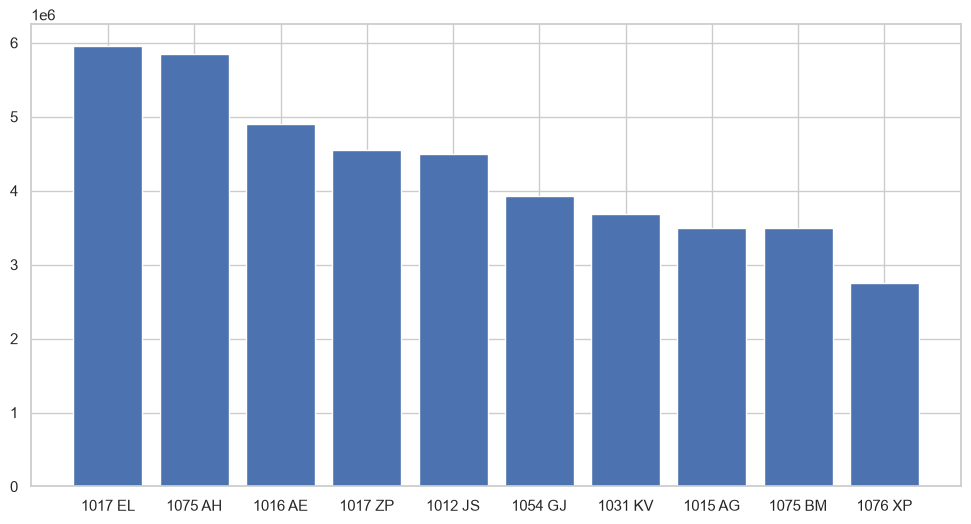

In [39]:
plt.figure(figsize=(12, 6))
x = houseprices_sorted['Zip'][0:10]
y = houseprices_sorted['Price'][0:10]
plt.bar(x, y)
plt.show()

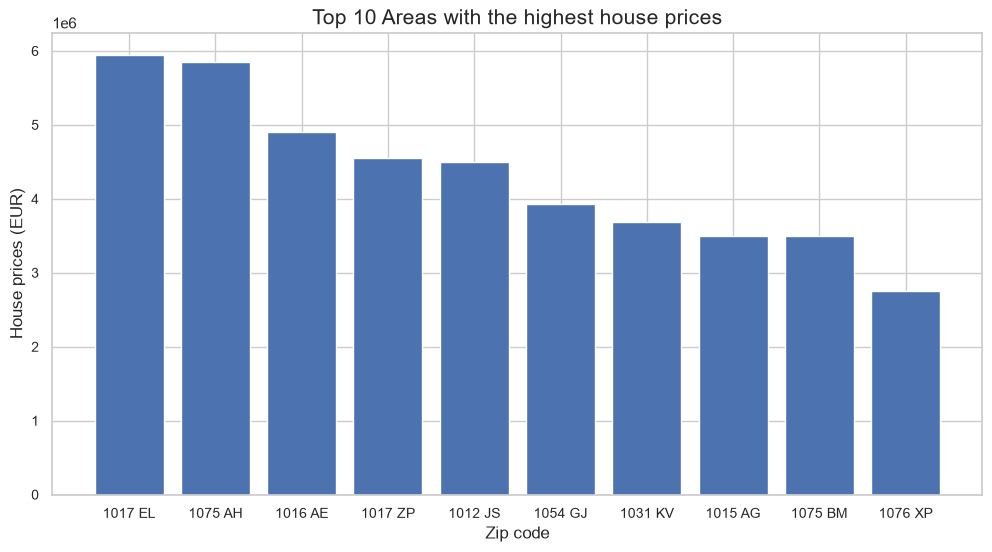

In [40]:
plt.figure(figsize=(12, 6))
plt.bar(x, y)
plt.title('Top 10 Areas with the highest house prices', fontsize=15)
plt.xlabel('Zip code', fontsize=12); plt.xticks(fontsize=10)
plt.ylabel('House prices (EUR)', fontsize=12); plt.yticks(fontsize=10)
plt.show()

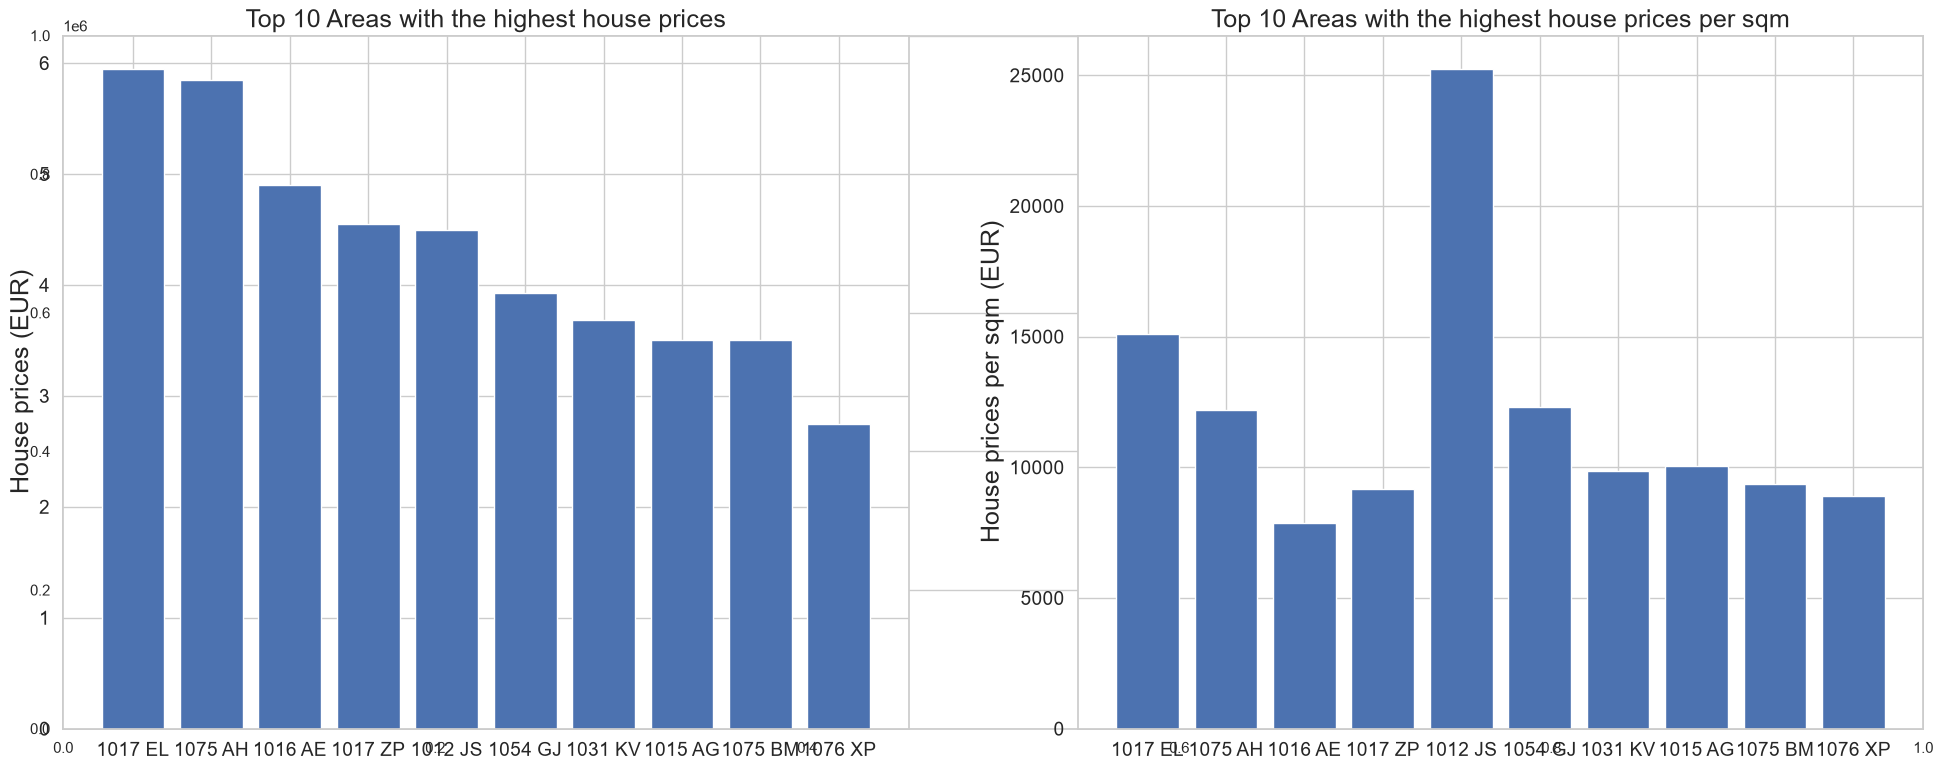

In [41]:
y1 = houseprices_sorted['PriceperSqm'][0:10]
fig, ax = plt.subplots(figsize=(24, 9))
plt.subplot(1, 2, 1)
plt.bar(x, y)
plt.xticks(fontsize=14); plt.ylabel('House prices (EUR)', fontsize=18); plt.yticks(fontsize=14)
plt.title('Top 10 Areas with the highest house prices', fontsize=18)
plt.subplot(1, 2, 2)
plt.bar(x, y1)
plt.xticks(fontsize=14); plt.ylabel('House prices per sqm (EUR)', fontsize=18); plt.yticks(fontsize=14)
plt.title('Top 10 Areas with the highest house prices per sqm', fontsize=18)
plt.show()

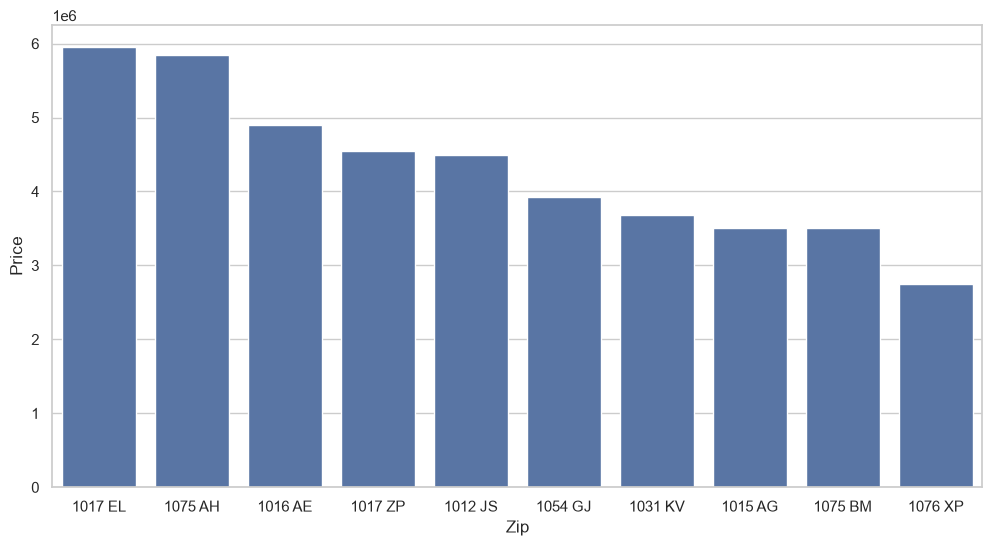

In [42]:
data = houseprices_sorted[0:10]
# case 1: basic
plt.figure(figsize=(12, 6))
sns.barplot(data=data, x='Zip', y='Price')
plt.show()

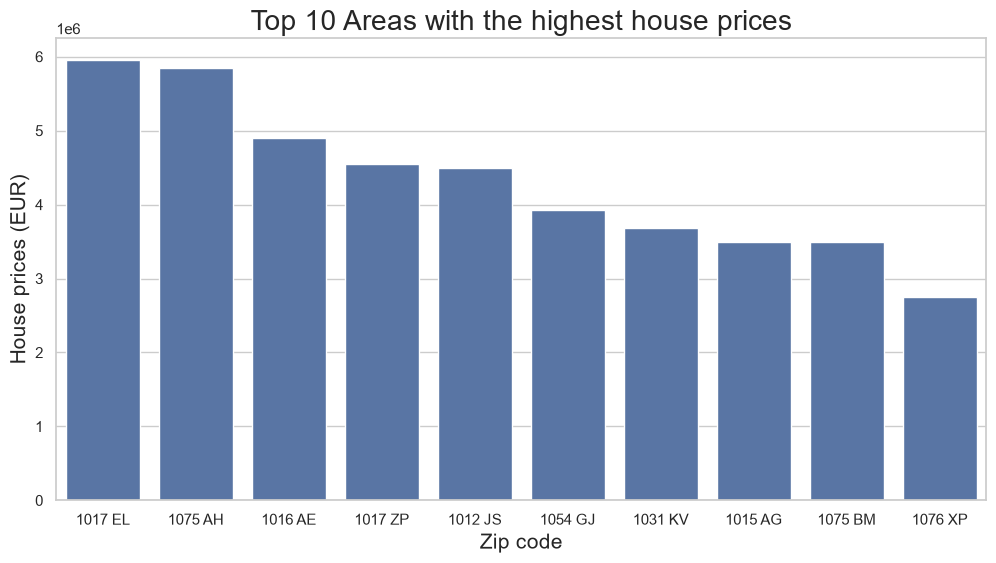

In [43]:
# case 2: advanced 1
plt.figure(figsize=(12, 6))
ax = sns.barplot(data=data, x='Zip', y='Price')
ax.set_xlabel('Zip code', fontsize=15)
ax.set_ylabel('House prices (EUR)', fontsize=15)
ax.set_title('Top 10 Areas with the highest house prices', fontsize=20)
plt.show()

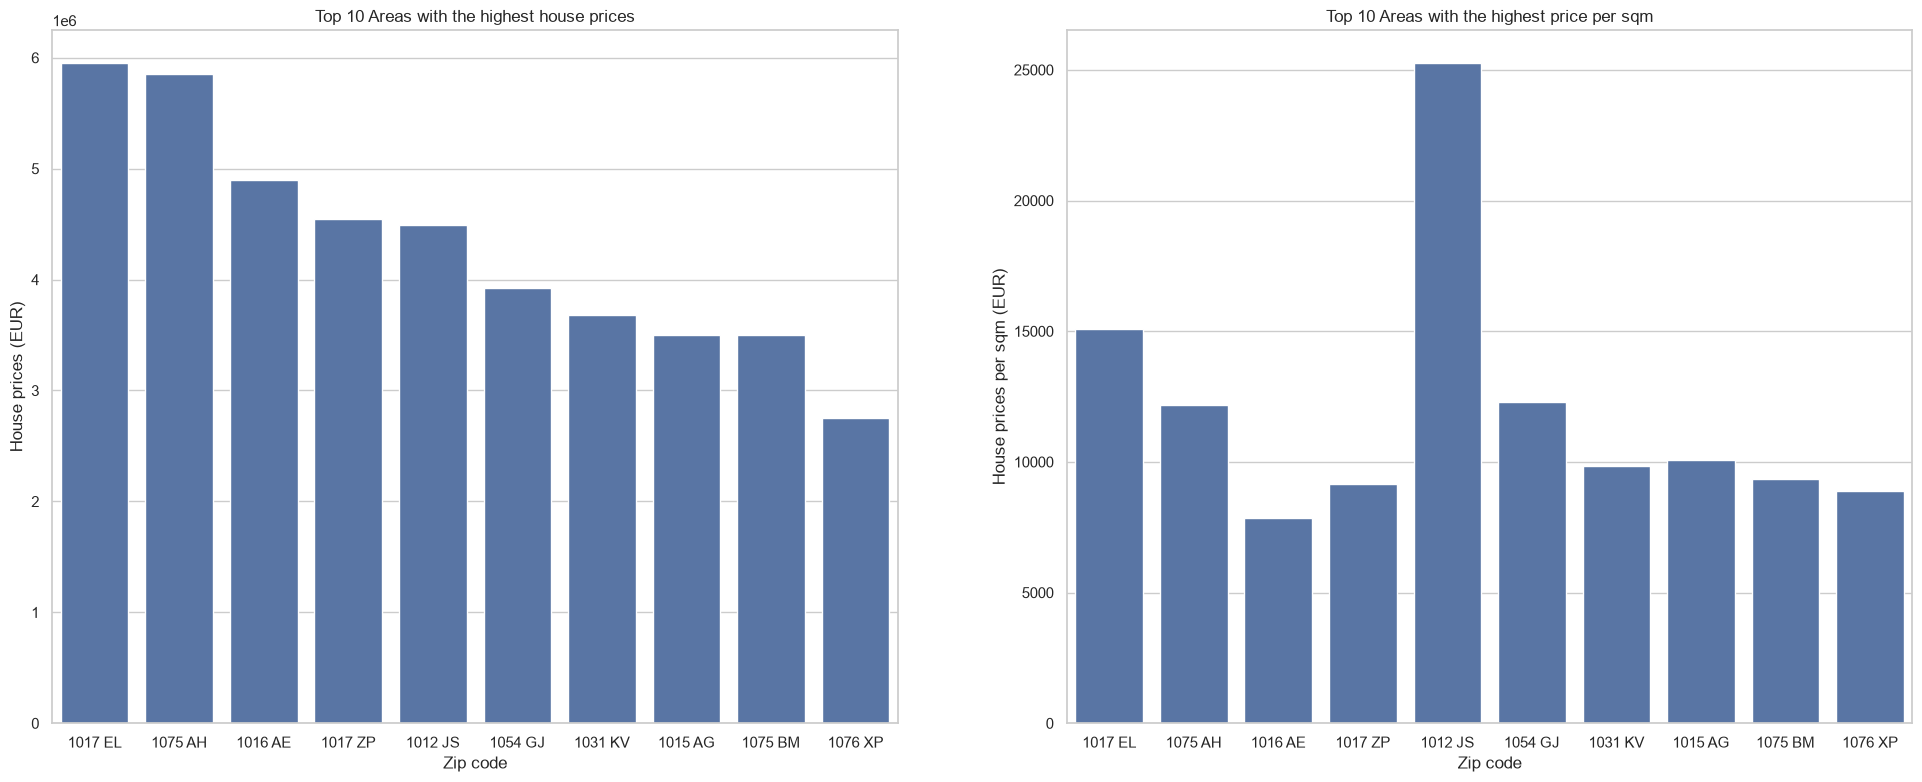

In [44]:
# case 3: nhiều góc nhìn cùng lúc
fig, ax = plt.subplots(1, 2, figsize=(24, 9))
ax1 = sns.barplot(data=data, x='Zip', y='Price', ax=ax[0])
ax1.set_xlabel('Zip code'); ax1.set_ylabel('House prices (EUR)')
ax1.set_title('Top 10 Areas with the highest house prices')
ax2 = sns.barplot(data=data, x='Zip', y='PriceperSqm', ax=ax[1])
ax2.set_xlabel('Zip code'); ax2.set_ylabel('House prices per sqm (EUR)')
ax2.set_title('Top 10 Areas with the highest price per sqm')
plt.show()

In [45]:
print('Top 10 theo Price      :', list(data['Zip']))
print('Zip có PriceperSqm cao nhất trong top 10:', data.loc[data['PriceperSqm'].idxmax(), 'Zip'])
data[['Zip','Price','Area','Room','PriceperSqm']].round(0)

Top 10 theo Price      : ['1017 EL', '1075 AH', '1016 AE', '1017 ZP', '1012 JS', '1054 GJ', '1031 KV', '1015 AG', '1075 BM', '1076 XP']
Zip có PriceperSqm cao nhất trong top 10: 1012 JS


,Zip,Price,Area,Room,PriceperSqm
195,1017 EL,5950000.0,394,10,15102.0
837,1075 AH,5850000.0,480,14,12188.0
305,1016 AE,4900000.0,623,13,7865.0
103,1017 ZP,4550000.0,497,13,9155.0
179,1012 JS,4495000.0,178,5,25253.0
33,1054 GJ,3925000.0,319,7,12304.0
301,1031 KV,3680000.0,374,4,9840.0
334,1015 AG,3500000.0,348,8,10057.0
276,1075 BM,3500000.0,374,7,9358.0
264,1076 XP,2750000.0,309,8,8900.0


## Bài tập thực hành 1 – Trực quan hóa dữ liệu Red Wine Quality

In [46]:
wine = pd.read_csv("data/winequality-red.csv")
features = [c for c in wine.columns if c != 'quality']
wine.shape

(1599, 12)

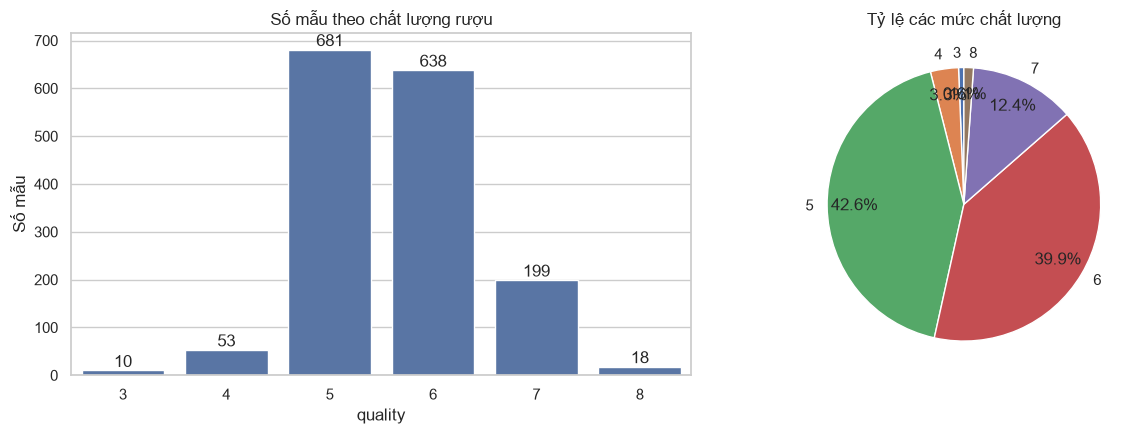

In [47]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
sns.countplot(data=wine, x='quality', ax=ax[0])
ax[0].set_title('Số mẫu theo chất lượng rượu'); ax[0].set_xlabel('quality'); ax[0].set_ylabel('Số mẫu')
for p in ax[0].patches:
    ax[0].annotate(int(p.get_height()), (p.get_x()+p.get_width()/2, p.get_height()), ha='center', va='bottom')
counts = wine['quality'].value_counts().sort_index()
ax[1].pie(counts, labels=counts.index, autopct='%1.1f%%', startangle=90, pctdistance=0.8)
ax[1].set_title('Tỷ lệ các mức chất lượng')
plt.tight_layout(); plt.show()

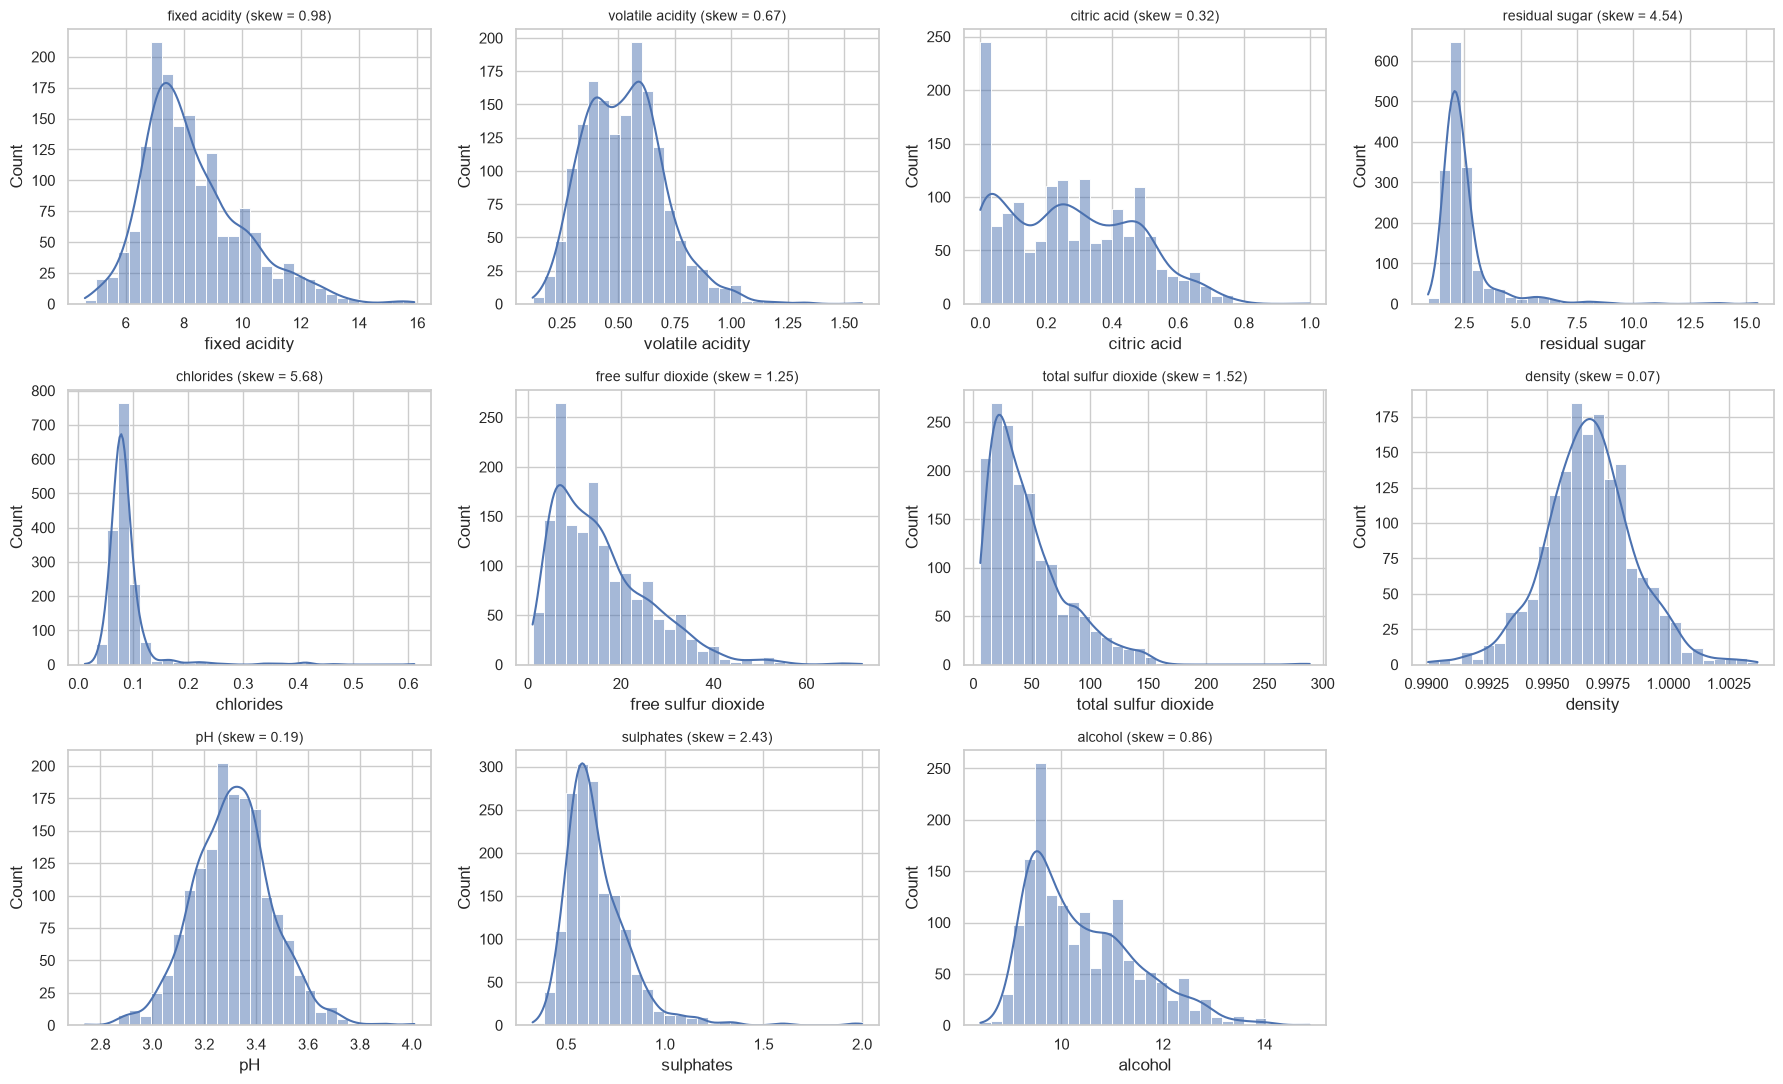

In [48]:
fig, axes = plt.subplots(3, 4, figsize=(18, 11))
for ax, col in zip(axes.flat, features):
    sns.histplot(wine[col], kde=True, bins=30, ax=ax)
    ax.set_title(f'{col} (skew = {wine[col].skew():.2f})', fontsize=10)
axes.flat[-1].axis('off')
plt.tight_layout(); plt.show()

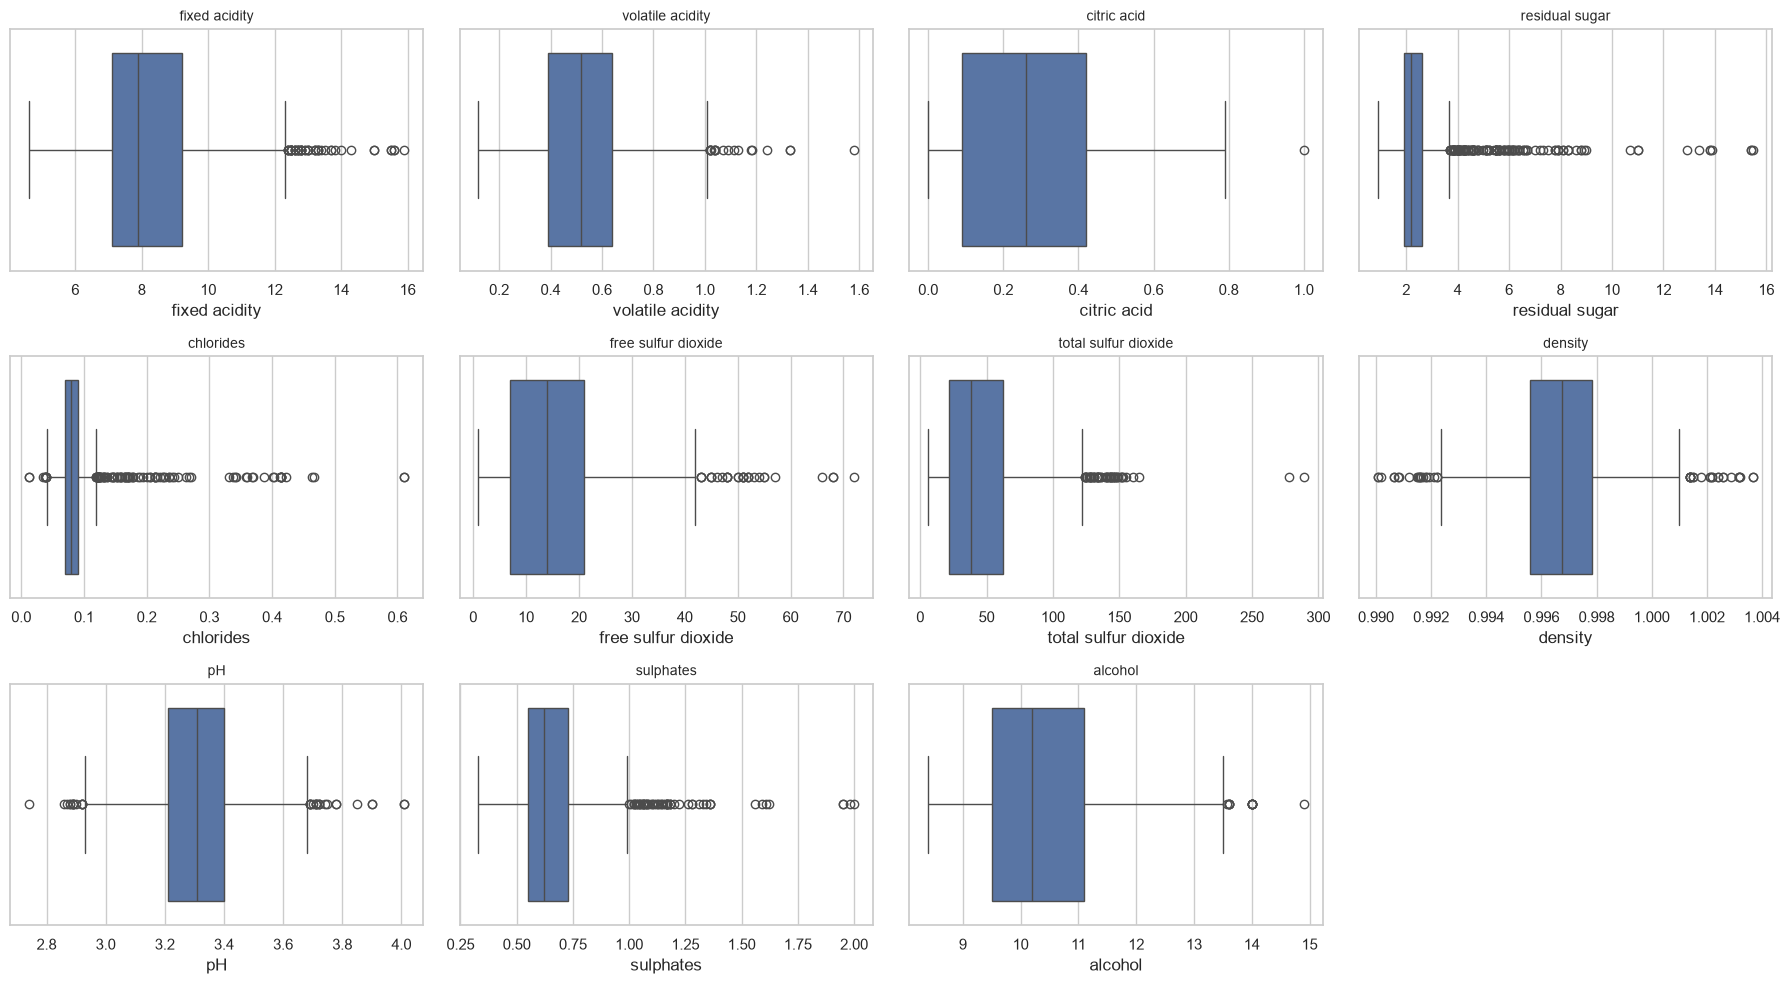

In [49]:
fig, axes = plt.subplots(3, 4, figsize=(18, 10))
for ax, col in zip(axes.flat, features):
    sns.boxplot(x=wine[col], ax=ax); ax.set_title(col, fontsize=10)
axes.flat[-1].axis('off')
plt.tight_layout(); plt.show()

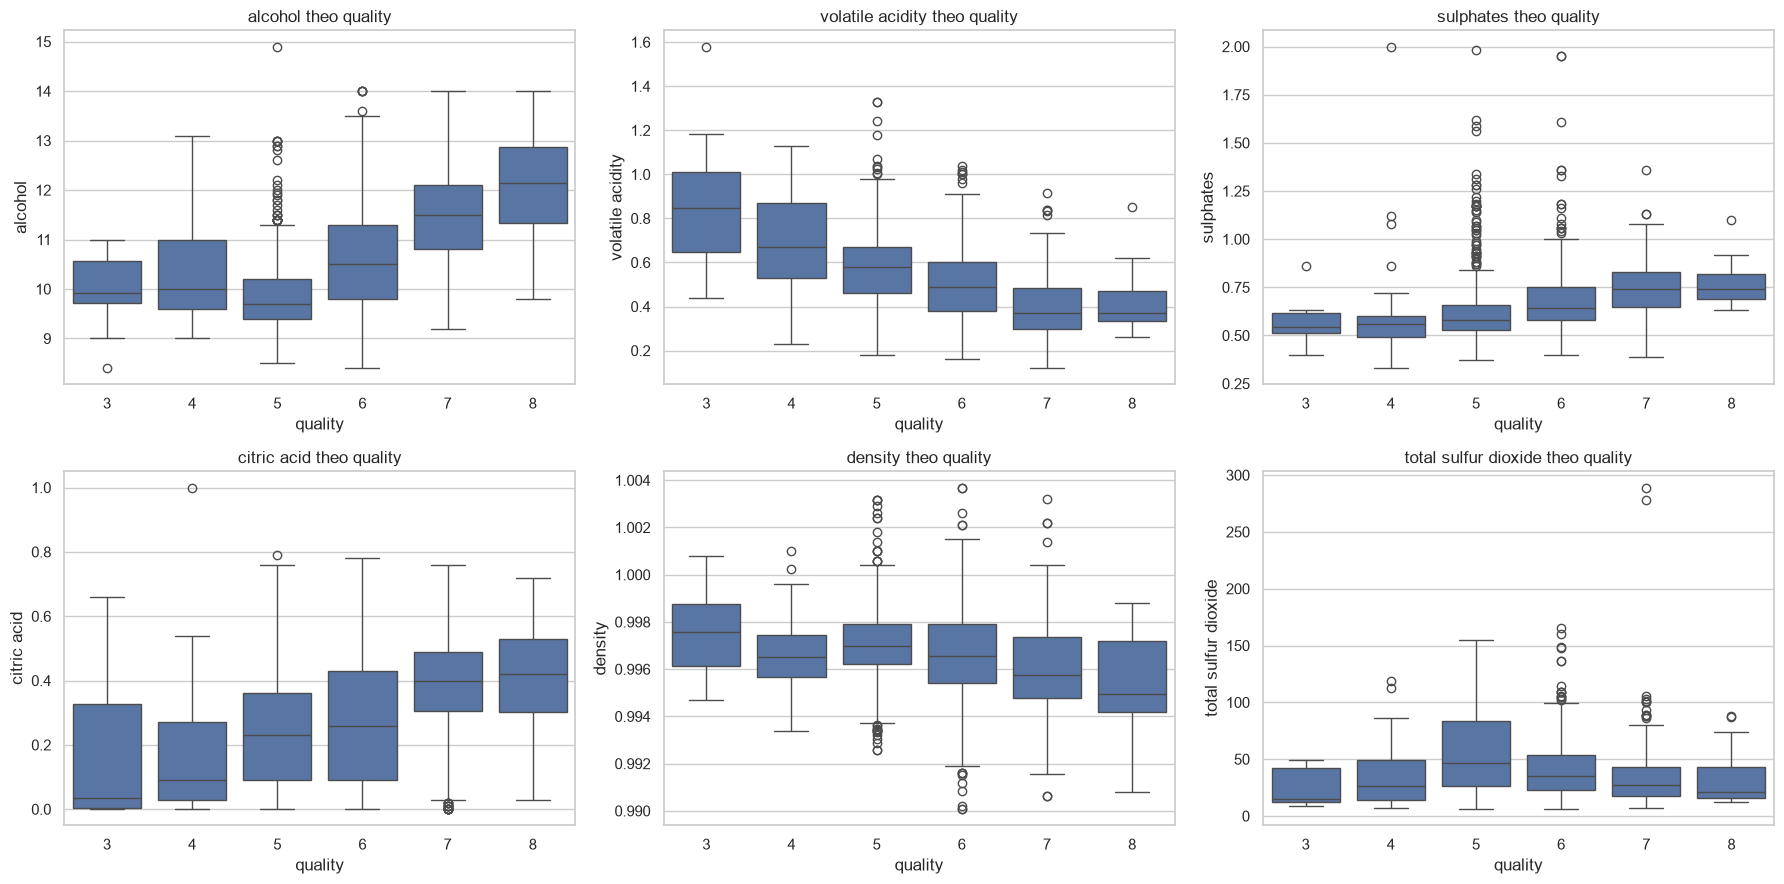

In [50]:
fig, axes = plt.subplots(2, 3, figsize=(18, 9))
for ax, col in zip(axes.flat, ['alcohol', 'volatile acidity', 'sulphates', 'citric acid', 'density', 'total sulfur dioxide']):
    sns.boxplot(data=wine, x='quality', y=col, ax=ax); ax.set_title(f'{col} theo quality')
plt.tight_layout(); plt.show()

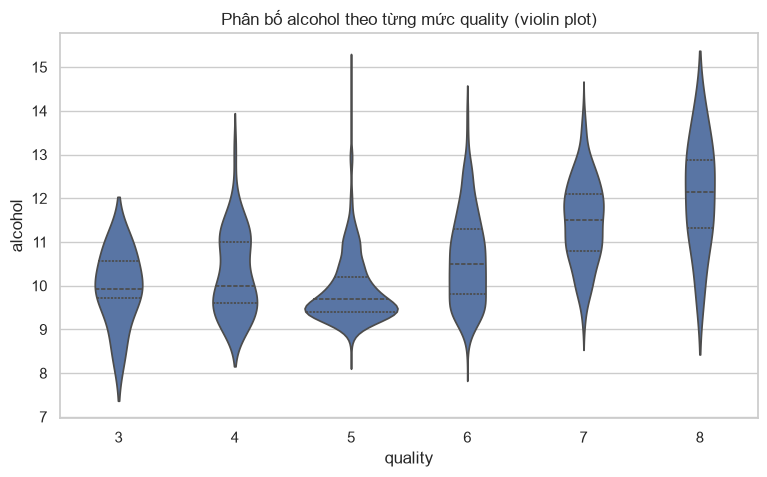

In [51]:
plt.figure(figsize=(9, 5))
sns.violinplot(data=wine, x='quality', y='alcohol', inner='quartile')
plt.title('Phân bố alcohol theo từng mức quality (violin plot)')
plt.show()

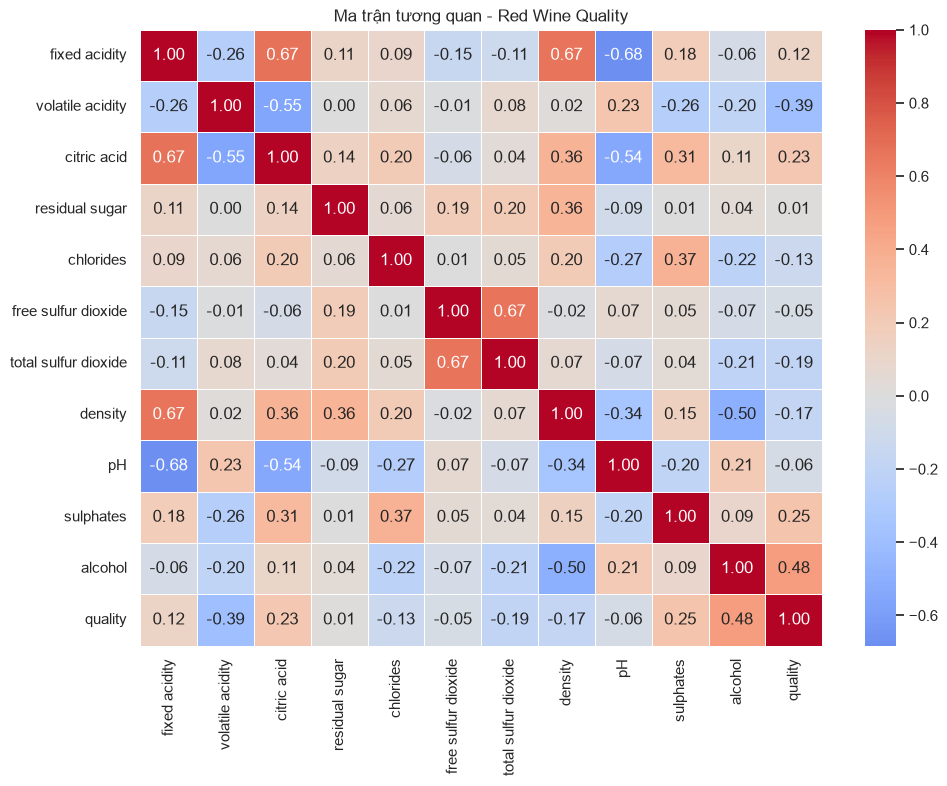

In [52]:
plt.figure(figsize=(11, 8))
sns.heatmap(wine.corr(), annot=True, fmt='.2f', cmap='coolwarm', center=0, linewidths=.5)
plt.title('Ma trận tương quan - Red Wine Quality')
plt.show()

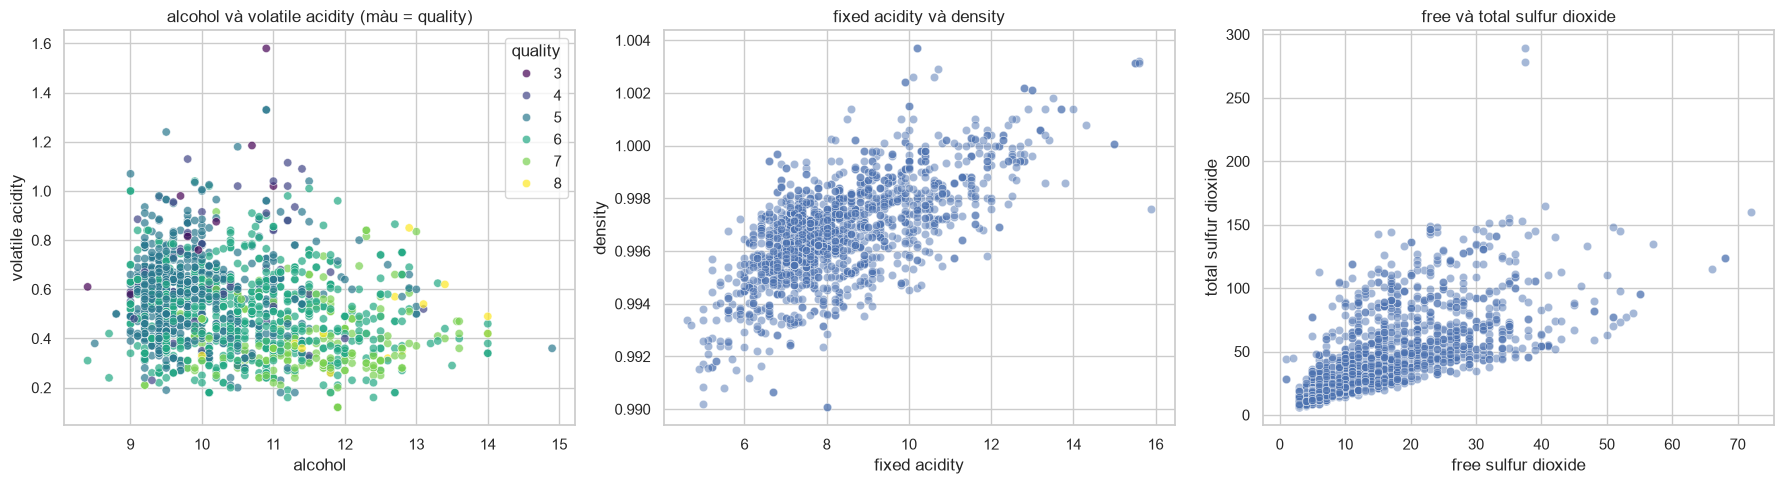

In [53]:
fig, ax = plt.subplots(1, 3, figsize=(18, 5))
sns.scatterplot(data=wine, x='alcohol', y='volatile acidity', hue='quality', palette='viridis', alpha=.7, ax=ax[0])
sns.scatterplot(data=wine, x='fixed acidity', y='density', alpha=.5, ax=ax[1])
sns.scatterplot(data=wine, x='free sulfur dioxide', y='total sulfur dioxide', alpha=.5, ax=ax[2])
ax[0].set_title('alcohol và volatile acidity (màu = quality)')
ax[1].set_title('fixed acidity và density'); ax[2].set_title('free và total sulfur dioxide')
plt.tight_layout(); plt.show()

In [54]:
print("corr(fixed acidity, density)            =", round(wine['fixed acidity'].corr(wine['density']), 3))
print("corr(fixed acidity, citric acid)         =", round(wine['fixed acidity'].corr(wine['citric acid']), 3))
print("corr(free SO2, total SO2)                =", round(wine['free sulfur dioxide'].corr(wine['total sulfur dioxide']), 3))
print("corr(alcohol, quality)                   =", round(wine['alcohol'].corr(wine['quality']), 3))
print("corr(volatile acidity, quality)          =", round(wine['volatile acidity'].corr(wine['quality']), 3))

corr(fixed acidity, density)            = 0.668
corr(fixed acidity, citric acid)         = 0.672
corr(free SO2, total SO2)                = 0.668
corr(alcohol, quality)                   = 0.476
corr(volatile acidity, quality)          = -0.391


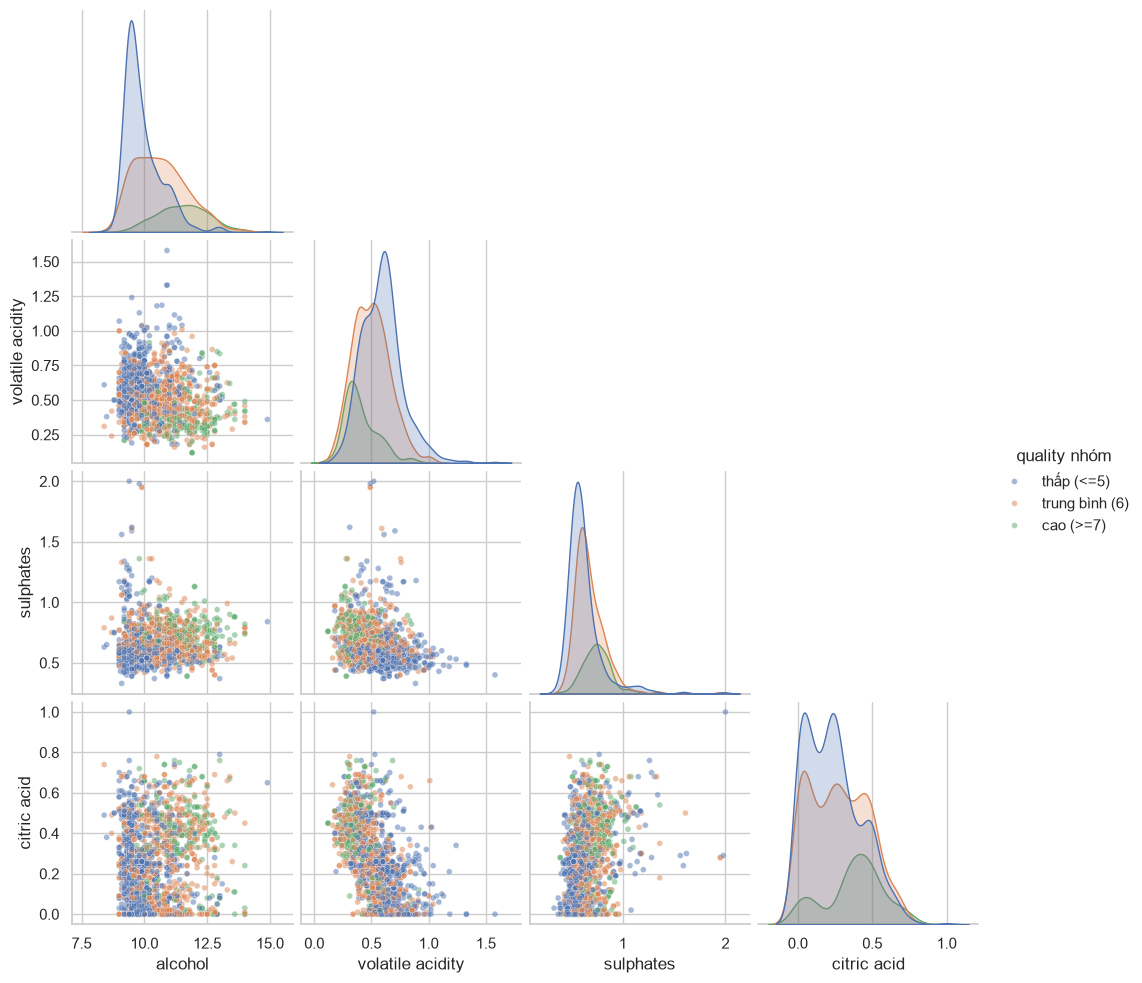

In [55]:
sub = wine[['alcohol', 'volatile acidity', 'sulphates', 'citric acid', 'quality']].copy()
sub['quality nhóm'] = pd.cut(sub['quality'], [0, 5, 6, 10], labels=['thấp (<=5)', 'trung bình (6)', 'cao (>=7)'])
sns.pairplot(sub.drop(columns='quality'), hue='quality nhóm', corner=True, plot_kws={'alpha': .5, 's': 18})
plt.show()

## Bài tập thực hành 2 – Trực quan hóa dữ liệu bệnh tiểu đường (Pima Indians)

In [56]:
diabetes = pd.read_csv("data/diabetes.csv")
cot_y_hoc = ['Glucose', 'BloodPressure', 'SkinThickness', 'Insulin', 'BMI']
d_feats = [c for c in diabetes.columns if c != 'Outcome']
diabetes.shape

(768, 9)

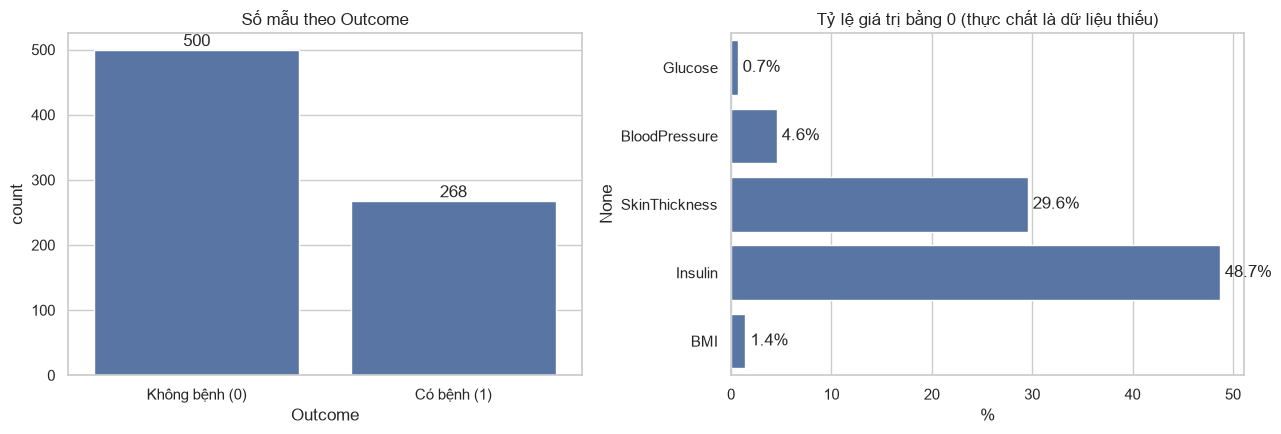

In [57]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
sns.countplot(data=diabetes, x='Outcome', ax=ax[0])
ax[0].set_xticks([0, 1]); ax[0].set_xticklabels(['Không bệnh (0)', 'Có bệnh (1)'])
ax[0].set_title('Số mẫu theo Outcome')
for p in ax[0].patches:
    ax[0].annotate(int(p.get_height()), (p.get_x()+p.get_width()/2, p.get_height()), ha='center', va='bottom')
zero_pct = (diabetes[cot_y_hoc] == 0).mean() * 100
sns.barplot(x=zero_pct.values, y=zero_pct.index, ax=ax[1])
ax[1].set_title('Tỷ lệ giá trị bằng 0 (thực chất là dữ liệu thiếu)'); ax[1].set_xlabel('%')
for i, v in enumerate(zero_pct.values): ax[1].text(v + .5, i, f'{v:.1f}%', va='center')
plt.tight_layout(); plt.show()

In [58]:
# Từ đây coi giá trị 0 ở các cột y học là thiếu
diabetes_clean = diabetes.copy()
diabetes_clean[cot_y_hoc] = diabetes_clean[cot_y_hoc].replace(0, np.nan)
diabetes_clean.isnull().sum()

Pregnancies                   0
Glucose                       5
BloodPressure                35
SkinThickness               227
Insulin                     374
BMI                          11
DiabetesPedigreeFunction      0
Age                           0
Outcome                       0
dtype: int64

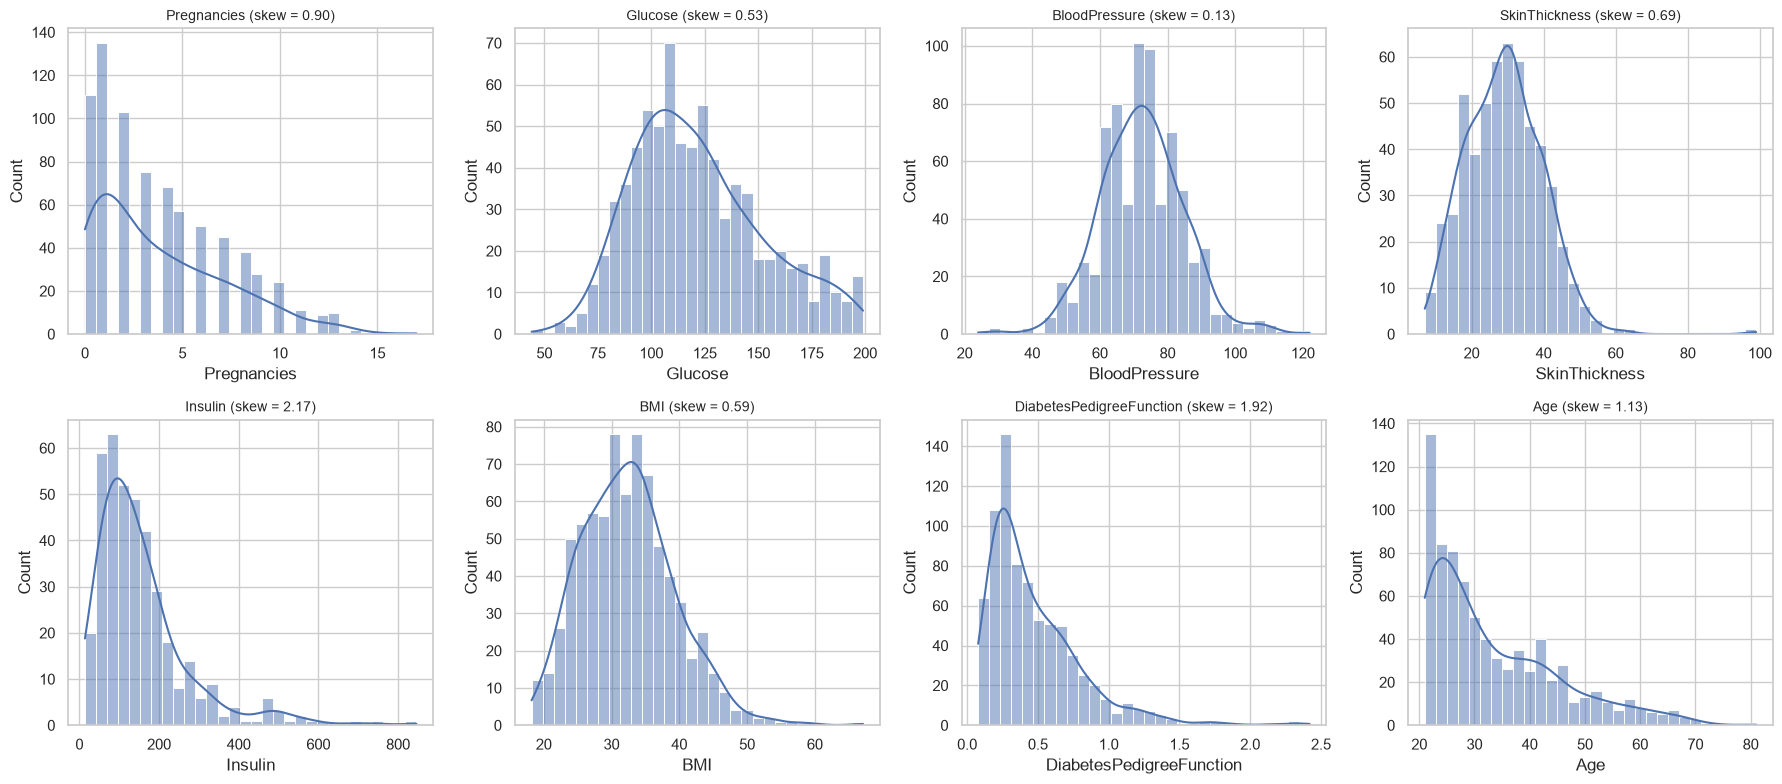

In [59]:
fig, axes = plt.subplots(2, 4, figsize=(18, 8))
for ax, col in zip(axes.flat, d_feats):
    sns.histplot(diabetes_clean[col].dropna(), kde=True, bins=30, ax=ax)
    ax.set_title(f'{col} (skew = {diabetes_clean[col].skew():.2f})', fontsize=10)
plt.tight_layout(); plt.show()

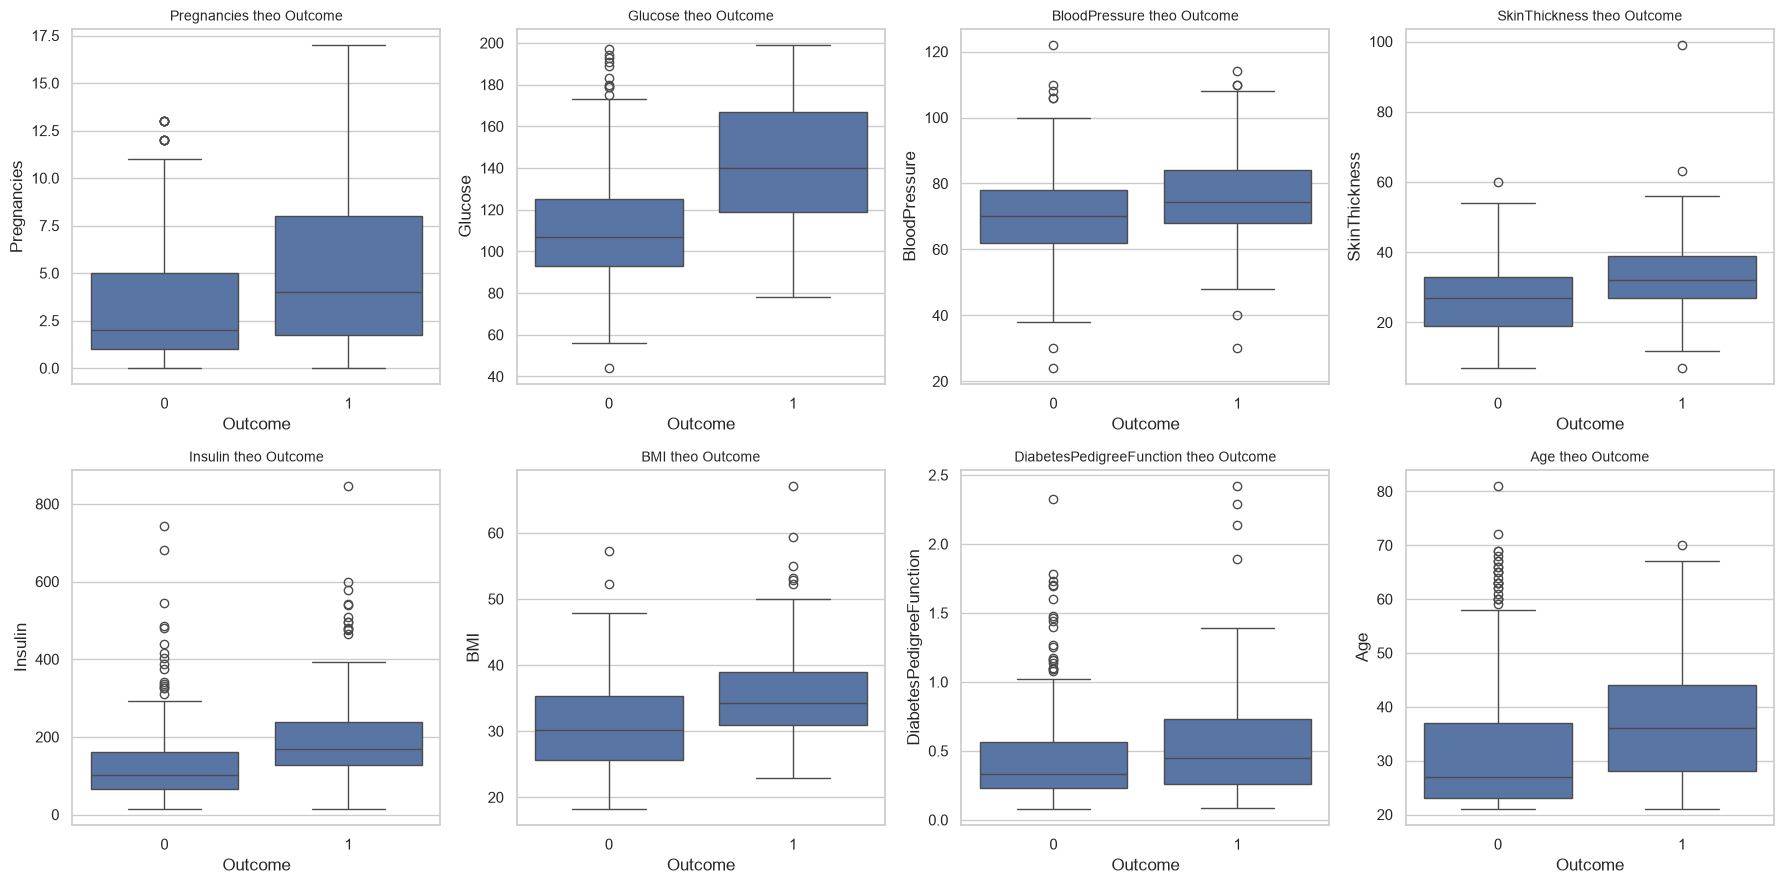

In [60]:
fig, axes = plt.subplots(2, 4, figsize=(18, 9))
for ax, col in zip(axes.flat, d_feats):
    sns.boxplot(data=diabetes_clean, x='Outcome', y=col, ax=ax); ax.set_title(f'{col} theo Outcome', fontsize=10)
plt.tight_layout(); plt.show()

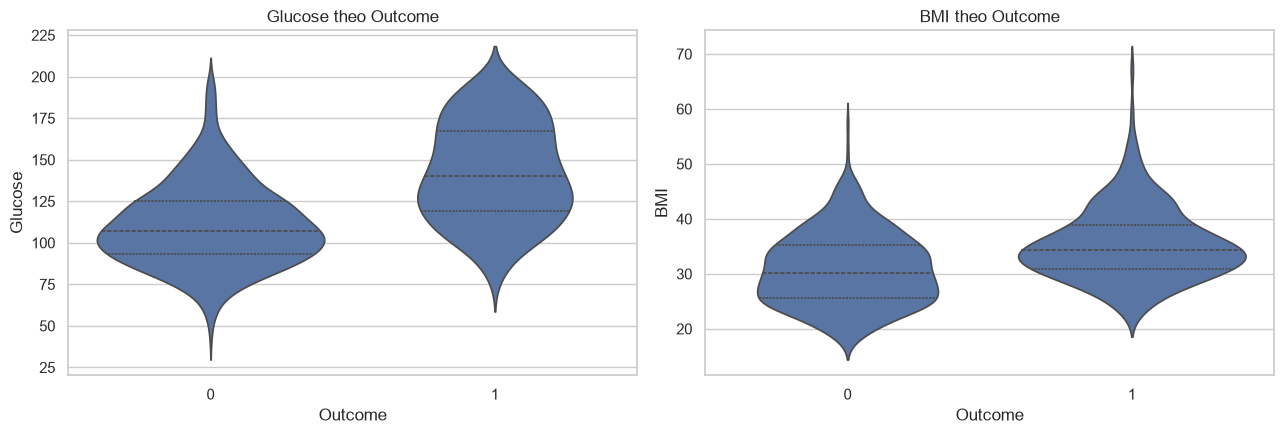

In [61]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
sns.violinplot(data=diabetes_clean, x='Outcome', y='Glucose', inner='quartile', ax=ax[0])
sns.violinplot(data=diabetes_clean, x='Outcome', y='BMI', inner='quartile', ax=ax[1])
ax[0].set_title('Glucose theo Outcome'); ax[1].set_title('BMI theo Outcome')
plt.tight_layout(); plt.show()

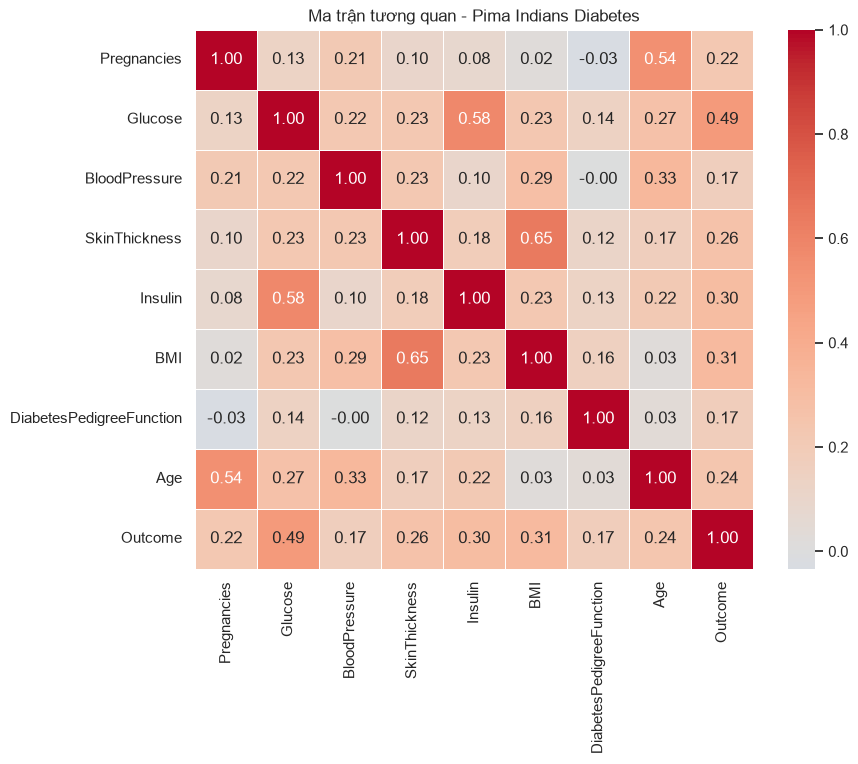

In [62]:
plt.figure(figsize=(9, 7))
sns.heatmap(diabetes_clean.corr(), annot=True, fmt='.2f', cmap='coolwarm', center=0, linewidths=.5)
plt.title('Ma trận tương quan - Pima Indians Diabetes')
plt.show()

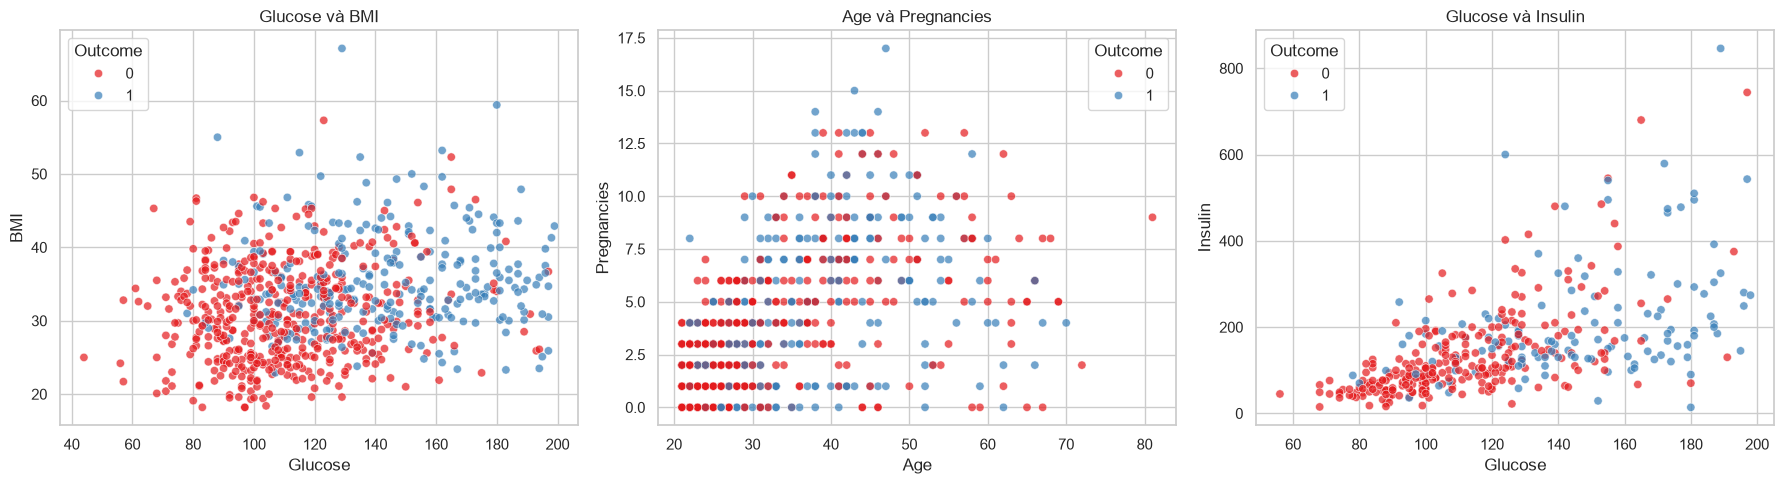

In [63]:
fig, ax = plt.subplots(1, 3, figsize=(18, 5))
sns.scatterplot(data=diabetes_clean, x='Glucose', y='BMI', hue='Outcome', palette='Set1', alpha=.7, ax=ax[0])
sns.scatterplot(data=diabetes_clean, x='Age', y='Pregnancies', hue='Outcome', palette='Set1', alpha=.7, ax=ax[1])
sns.scatterplot(data=diabetes_clean, x='Glucose', y='Insulin', hue='Outcome', palette='Set1', alpha=.7, ax=ax[2])
ax[0].set_title('Glucose và BMI'); ax[1].set_title('Age và Pregnancies'); ax[2].set_title('Glucose và Insulin')
plt.tight_layout(); plt.show()

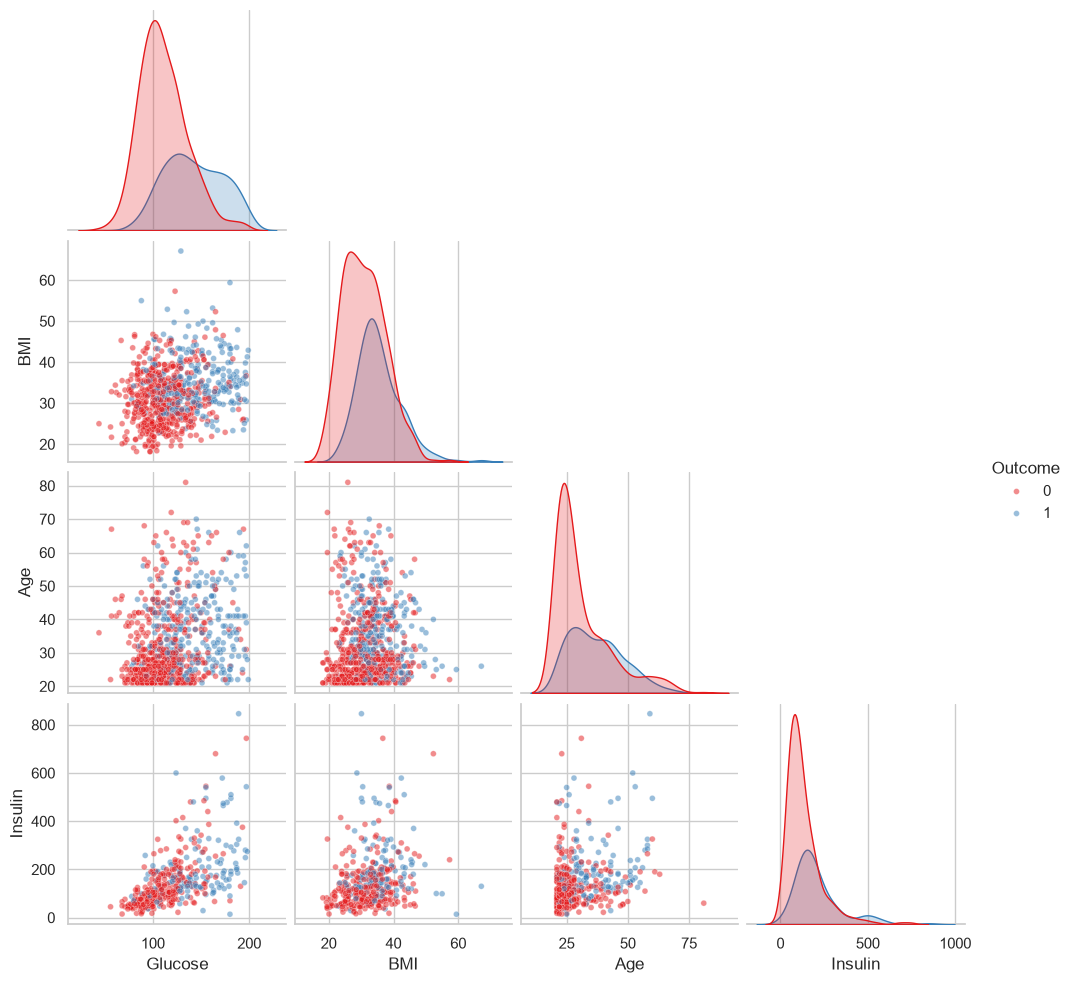

In [64]:
sns.pairplot(diabetes_clean[['Glucose', 'BMI', 'Age', 'Insulin', 'Outcome']], hue='Outcome', palette='Set1',
             corner=True, plot_kws={'alpha': .5, 's': 18})
plt.show()

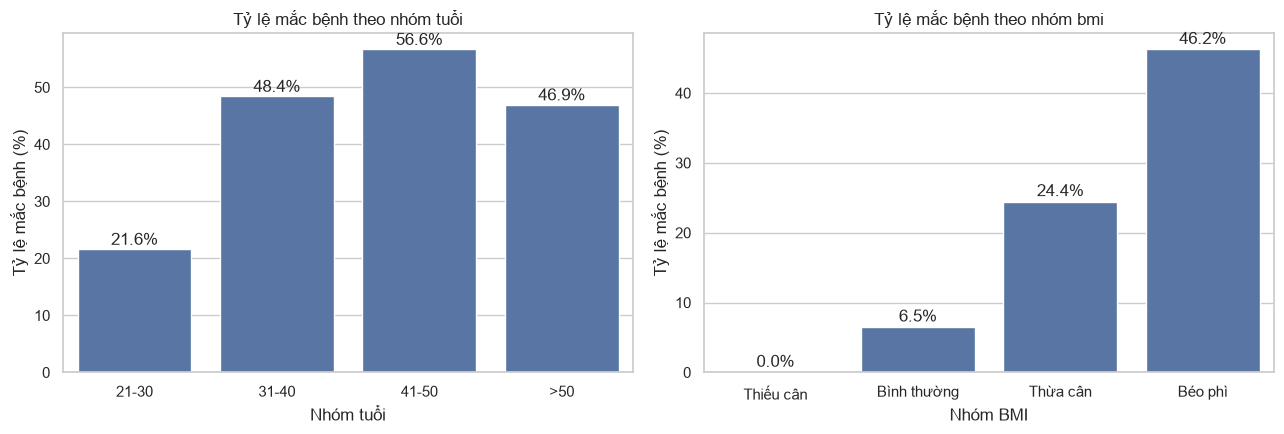

In [65]:
tmp = diabetes_clean.copy()
tmp['Nhóm tuổi'] = pd.cut(tmp['Age'], [20, 30, 40, 50, 100], labels=['21-30', '31-40', '41-50', '>50'])
tmp['Nhóm BMI'] = pd.cut(tmp['BMI'], [0, 18.5, 25, 30, 100], labels=['Thiếu cân', 'Bình thường', 'Thừa cân', 'Béo phì'])
fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
for a, col in zip(ax, ['Nhóm tuổi', 'Nhóm BMI']):
    rate = tmp.groupby(col, observed=True)['Outcome'].mean() * 100
    sns.barplot(x=rate.index.astype(str), y=rate.values, ax=a)
    a.set_ylabel('Tỷ lệ mắc bệnh (%)'); a.set_title(f'Tỷ lệ mắc bệnh theo {col.lower()}')
    for i, v in enumerate(rate.values): a.text(i, v + .8, f'{v:.1f}%', ha='center')
plt.tight_layout(); plt.show()

## Bài tập thực hành 2 (tiếp) – EDA tập dữ liệu mua sắm siêu thị (Online Retail)

In [66]:
df = pd.read_excel("data/Online Retail.xlsx")
df = df[['CustomerID', 'InvoiceNo', 'StockCode', 'Quantity', 'UnitPrice', 'Description', 'InvoiceDate', 'Country']]
print(df.shape)
df.head(10)

(541909, 8)


,CustomerID,InvoiceNo,StockCode,Quantity,UnitPrice,Description,InvoiceDate,Country
0,17850.0,536365,85123A,6,2.55,WHITE HANGING HEART T-LIGHT HOLDER,2010-12-01 08:26:00,United Kingdom
1,17850.0,536365,71053,6,3.39,WHITE METAL LANTERN,2010-12-01 08:26:00,United Kingdom
2,17850.0,536365,84406B,8,2.75,CREAM CUPID HEARTS COAT HANGER,2010-12-01 08:26:00,United Kingdom
3,17850.0,536365,84029G,6,3.39,KNITTED UNION FLAG HOT WATER BOTTLE,2010-12-01 08:26:00,United Kingdom
4,17850.0,536365,84029E,6,3.39,RED WOOLLY HOTTIE WHITE HEART.,2010-12-01 08:26:00,United Kingdom
5,17850.0,536365,22752,2,7.65,SET 7 BABUSHKA NESTING BOXES,2010-12-01 08:26:00,United Kingdom
6,17850.0,536365,21730,6,4.25,GLASS STAR FROSTED T-LIGHT HOLDER,2010-12-01 08:26:00,United Kingdom
7,17850.0,536366,22633,6,1.85,HAND WARMER UNION JACK,2010-12-01 08:28:00,United Kingdom
8,17850.0,536366,22632,6,1.85,HAND WARMER RED POLKA DOT,2010-12-01 08:28:00,United Kingdom
9,13047.0,536367,84879,32,1.69,ASSORTED COLOUR BIRD ORNAMENT,2010-12-01 08:34:00,United Kingdom


In [67]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 541909 entries, 0 to 541908
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype         
---  ------       --------------   -----         
 0   CustomerID   406829 non-null  float64       
 1   InvoiceNo    541909 non-null  object        
 2   StockCode    541909 non-null  object        
 3   Quantity     541909 non-null  int64         
 4   UnitPrice    541909 non-null  float64       
 5   Description  540455 non-null  object        
 6   InvoiceDate  541909 non-null  datetime64[us]
 7   Country      541909 non-null  str           
dtypes: datetime64[us](1), float64(2), int64(1), object(3), str(1)
memory usage: 40.0+ MB


In [68]:
df.describe(include='all').T

,count,unique,top,freq,mean,min,25%,50%,75%,max,std
CustomerID,406829.0,NaN,NaN,NaN,15287.69057,12346.0,13953.0,15152.0,16791.0,18287.0,1713.600303
InvoiceNo,541909.0,25900.0,573585.0,1114.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN
StockCode,541909,4070,85123A,2313,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Quantity,541909.0,NaN,NaN,NaN,9.55225,-80995.0,1.0,3.0,10.0,80995.0,218.081158
UnitPrice,541909.0,NaN,NaN,NaN,4.611114,-11062.06,1.25,2.08,4.13,38970.0,96.759853
Description,540455,4223,WHITE HANGING HEART T-LIGHT HOLDER,2369,NaN,NaN,NaN,NaN,NaN,NaN,NaN
InvoiceDate,541909,NaN,NaN,NaN,2011-07-04 13:34:57.156386,2010-12-01 08:26:00,2011-03-28 11:34:00,2011-07-19 17:17:00,2011-10-19 11:27:00,2011-12-09 12:50:00,NaN
Country,541909,38,United Kingdom,495478,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [69]:
print("Giá trị thiếu:"); print(df.isna().sum())
print("Số dòng trùng lặp:", df.duplicated().sum())
print("Số quốc gia:", df['Country'].nunique())
print("Khoảng thời gian:", df['InvoiceDate'].min(), "->", df['InvoiceDate'].max())

Giá trị thiếu:
CustomerID     135080
InvoiceNo           0
StockCode           0
Quantity            0
UnitPrice           0
Description      1454
InvoiceDate         0
Country             0
dtype: int64
Số dòng trùng lặp: 5268
Số quốc gia: 38
Khoảng thời gian: 2010-12-01 08:26:00 -> 2011-12-09 12:50:00


In [70]:
print("Dòng Quantity < 0       :", (df['Quantity'] < 0).sum())
print("Hóa đơn hủy (mã bắt đầu 'C'):", df['InvoiceNo'].astype(str).str.startswith('C').sum())
print("Dòng UnitPrice = 0      :", (df['UnitPrice'] == 0).sum())
print("Dòng UnitPrice < 0      :", (df['UnitPrice'] < 0).sum())

Dòng Quantity < 0       : 10624
Hóa đơn hủy (mã bắt đầu 'C'): 9288
Dòng UnitPrice = 0      : 2515
Dòng UnitPrice < 0      : 2


In [71]:
df['TotalAmount'] = df['Quantity'] * df['UnitPrice']
df['Year'] = df['InvoiceDate'].dt.year
df['Month'] = df['InvoiceDate'].dt.to_period('M').astype(str)
df[['Quantity', 'UnitPrice', 'TotalAmount', 'Year', 'Month']].head()

,Quantity,UnitPrice,TotalAmount,Year,Month
0,6,2.55,15.30,2010,2010-12
1,6,3.39,20.34,2010,2010-12
2,8,2.75,22.00,2010,2010-12
3,6,3.39,20.34,2010,2010-12
4,6,3.39,20.34,2010,2010-12


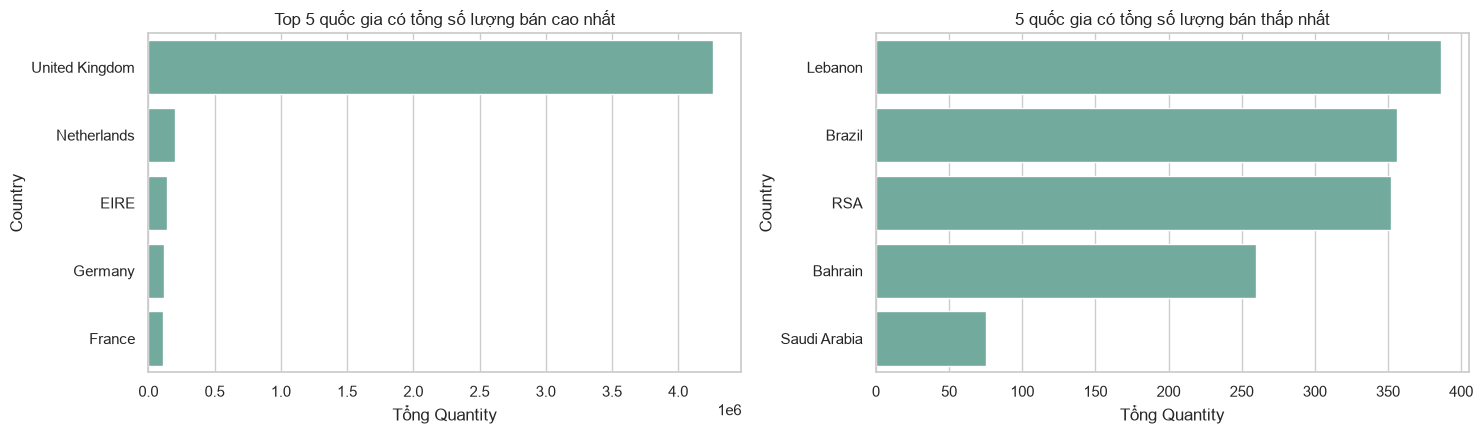

In [72]:
country_qty = df.groupby('Country')['Quantity'].sum().sort_values(ascending=False)
fig, ax = plt.subplots(1, 2, figsize=(15, 4.5))
sns.barplot(x=country_qty.head(5).values, y=country_qty.head(5).index, color='#69b3a2', ax=ax[0])
ax[0].set_title('Top 5 quốc gia có tổng số lượng bán cao nhất'); ax[0].set_xlabel('Tổng Quantity')
sns.barplot(x=country_qty.tail(5).values, y=country_qty.tail(5).index, color='#69b3a2', ax=ax[1])
ax[1].set_title('5 quốc gia có tổng số lượng bán thấp nhất'); ax[1].set_xlabel('Tổng Quantity')
plt.tight_layout(); plt.show()

In [73]:
country_qty.head(10).to_frame('Quantity')

,Quantity
Country,
United Kingdom,4263829
Netherlands,200128
EIRE,142637
Germany,117448
France,110480
Australia,83653
Sweden,35637
Switzerland,30325
Spain,26824


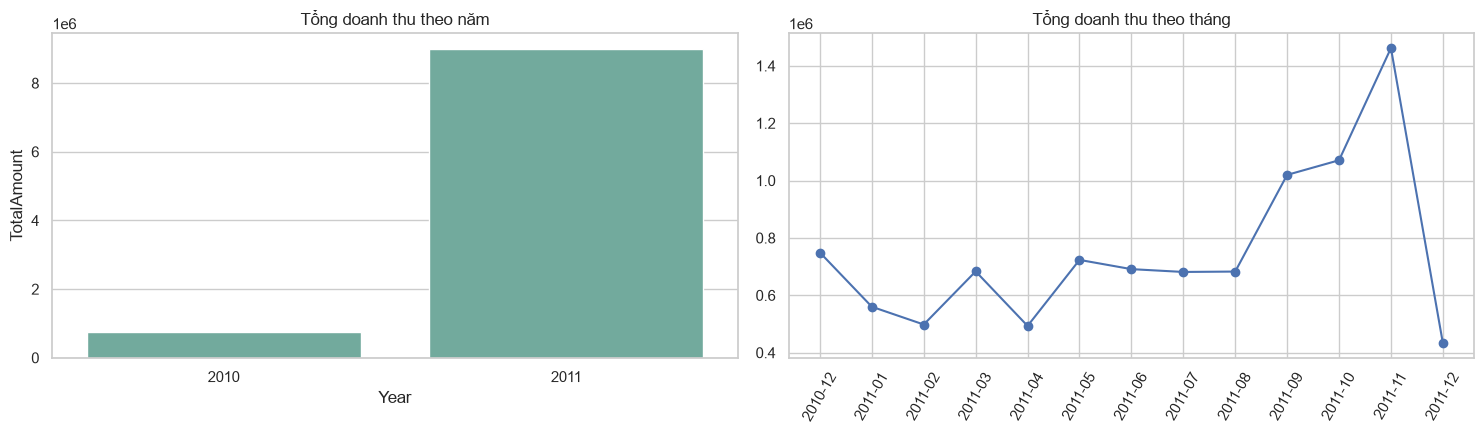

Year
2010     748957.0
2011    8998791.0
Name: TotalAmount, dtype: float64

In [74]:
fig, ax = plt.subplots(1, 2, figsize=(15, 4.5))
year_amt = df.groupby('Year')['TotalAmount'].sum()
sns.barplot(x=year_amt.index.astype(str), y=year_amt.values, color='#69b3a2', ax=ax[0])
ax[0].set_title('Tổng doanh thu theo năm'); ax[0].set_ylabel('TotalAmount')
month_amt = df.groupby('Month')['TotalAmount'].sum()
ax[1].plot(month_amt.index, month_amt.values, marker='o')
ax[1].set_title('Tổng doanh thu theo tháng'); ax[1].tick_params(axis='x', rotation=60)
plt.tight_layout(); plt.show()
year_amt.round(0)

Sau khi bỏ dòng thiếu CustomerID: (406829, 11) (bỏ 135080 dòng)


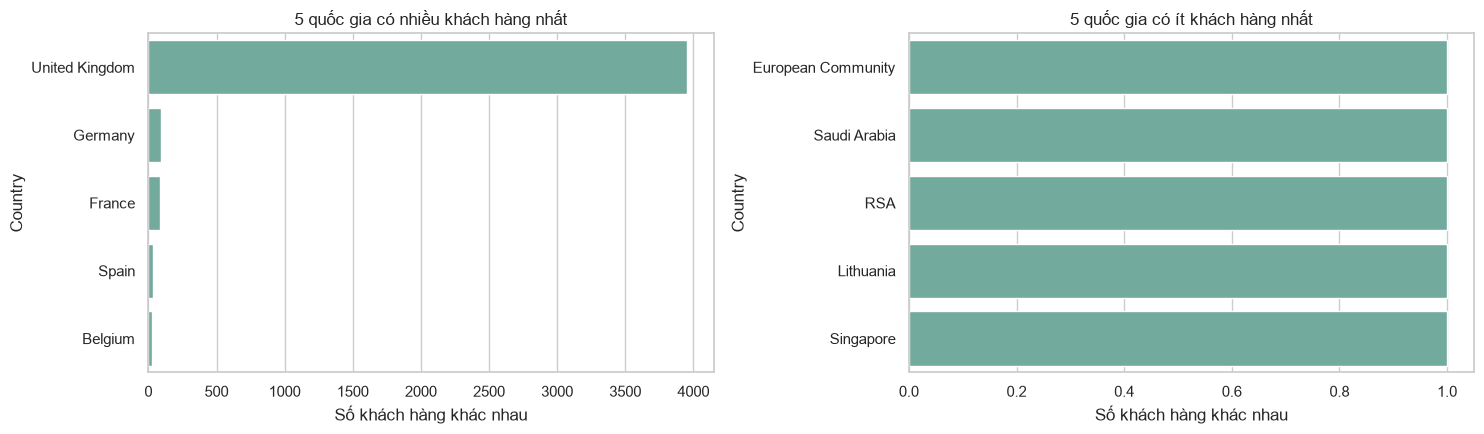

Country
United Kingdom    3950
Germany             95
France              87
Spain               31
Belgium             25
Name: CustomerID, dtype: int64

In [75]:
df_clean = df.dropna(subset=['CustomerID'])
print("Sau khi bỏ dòng thiếu CustomerID:", df_clean.shape, "(bỏ", len(df) - len(df_clean), "dòng)")
cus = df_clean.groupby('Country')['CustomerID'].nunique().sort_values(ascending=False)
fig, ax = plt.subplots(1, 2, figsize=(15, 4.5))
sns.barplot(x=cus.head(5).values, y=cus.head(5).index, color='#69b3a2', ax=ax[0]); ax[0].set_title('5 quốc gia có nhiều khách hàng nhất')
sns.barplot(x=cus.tail(5).values, y=cus.tail(5).index, color='#69b3a2', ax=ax[1]); ax[1].set_title('5 quốc gia có ít khách hàng nhất')
for a in ax: a.set_xlabel('Số khách hàng khác nhau')
plt.tight_layout(); plt.show()
cus.head(5)

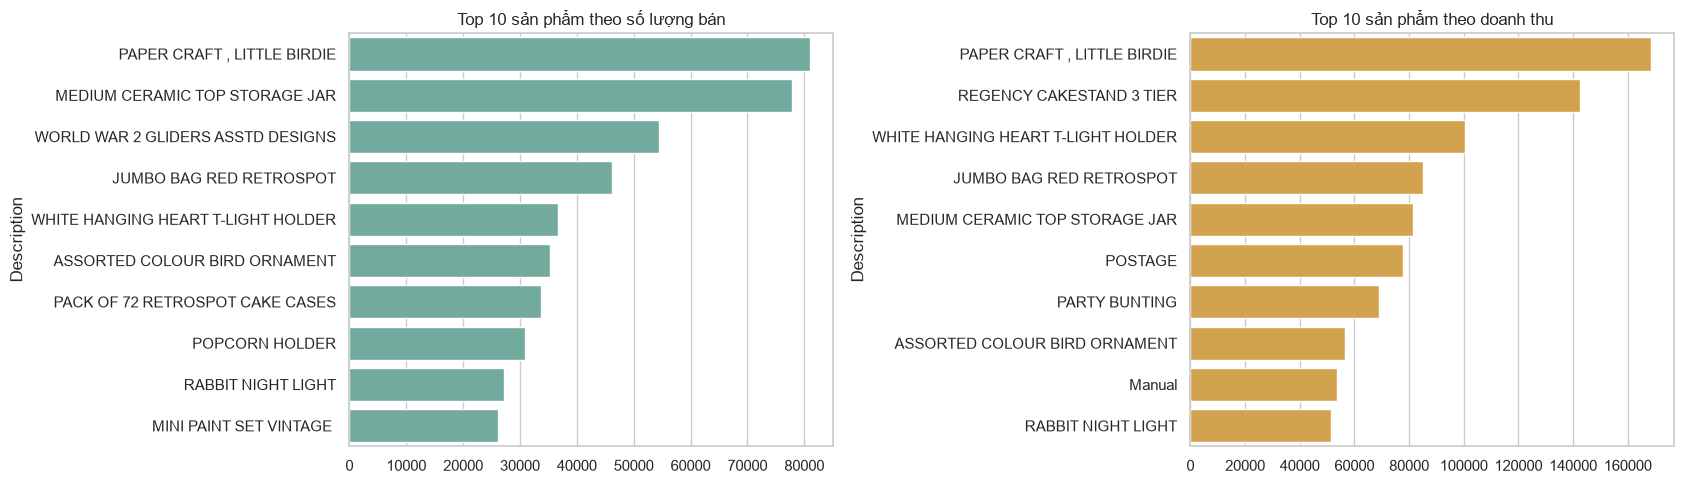

In [76]:
valid = df_clean[(df_clean['Quantity'] > 0) & (df_clean['UnitPrice'] > 0)]
top_qty = valid.groupby('Description')['Quantity'].sum().sort_values(ascending=False).head(10)
top_rev = valid.groupby('Description')['TotalAmount'].sum().sort_values(ascending=False).head(10)
fig, ax = plt.subplots(1, 2, figsize=(17, 5))
sns.barplot(x=top_qty.values, y=top_qty.index, color='#69b3a2', ax=ax[0]); ax[0].set_title('Top 10 sản phẩm theo số lượng bán')
sns.barplot(x=top_rev.values, y=top_rev.index, color='#e8a838', ax=ax[1]); ax[1].set_title('Top 10 sản phẩm theo doanh thu')
plt.tight_layout(); plt.show()

In [77]:
avg_sales = (valid.groupby(['StockCode', 'Description'])
                  .agg(TotalAmount=('TotalAmount', 'mean'), Quantity=('Quantity', 'mean'))
                  .sort_values('Quantity', ascending=False))
avg_sales.head(10).round(2)

,,TotalAmount,Quantity
StockCode,Description,,
23843,"PAPER CRAFT , LITTLE BIRDIE",168469.60,80995.00
47556B,TEA TIME TEA TOWELS,3022.50,1300.00
84568,GIRLS ALPHABET IRON ON PATCHES,97.20,520.00
23166,MEDIUM CERAMIC TOP STORAGE JAR,411.20,393.52
18007,ESSENTIAL BALM 3.5g TIN IN ENVELOPE,21.32,325.33
20914,SET/5 RED SPOTTY LID GLASS BOWLS,734.40,288.00
84598,BOYS ALPHABET IRON ON PATCHES,52.42,249.60
16014,SMALL CHINESE STYLE SCISSOR,80.29,246.81
23131,MISELTOE HEART WREATH CREAM,996.00,240.00


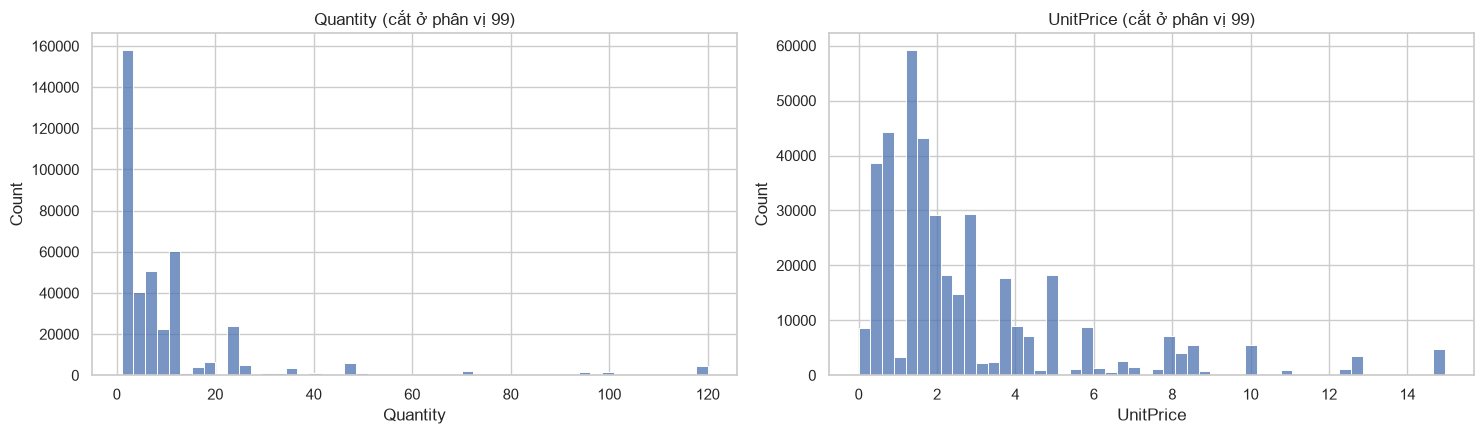

In [78]:
fig, ax = plt.subplots(1, 2, figsize=(15, 4.5))
sns.histplot(valid['Quantity'].clip(upper=valid['Quantity'].quantile(.99)), bins=50, ax=ax[0])
ax[0].set_title('Quantity (cắt ở phân vị 99)')
sns.histplot(valid['UnitPrice'].clip(upper=valid['UnitPrice'].quantile(.99)), bins=50, ax=ax[1])
ax[1].set_title('UnitPrice (cắt ở phân vị 99)')
plt.tight_layout(); plt.show()